# Lab: Build your first image encoder–decoder

**Time:** 60–90 minutes. **Prerequisites:** Python, tensors, basic convolutions, and gradient descent.

Read [CNN-Based Encoder–Decoder Architectures for Images](../../lectures/encoder_decoder/encoder_decoder.md), especially Sections 2–7.

You will reconstruct handwritten digits using a small convolutional network. Each image is both the input and the target: this training task makes our encoder–decoder an **autoencoder**. Digit labels are not used for training.

By the end, you should be able to:
- implement an encoder, spatial latent representation, and decoder;
- trace `[N, C, H, W]` shapes through downsampling and upsampling;
- train with reconstruction MSE and inspect held-out reconstructions;
- measure latent size and explain the bottleneck trade-off.

All four implementation exercises and the written answers are completed below. Run cells in order to reproduce the training, evaluation, and bottleneck comparison.

## 1. Set up and load data (10 minutes)
Use a Python 3 notebook kernel. If needed, uncomment the installation cell, run it once, and restart the kernel. A GPU is optional. The first dataset load needs internet access; later runs use the local cache. `ToTensor()` scales MNIST pixels to `[0, 1]`; do not apply mean/std normalization for this lab.

In [1]:
# %pip install torch torchvision matplotlib

Device: cpu
Batch: (64, 1, 28, 28) Pixel range: 0.0 1.0


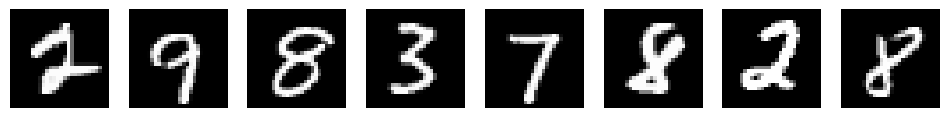

In [2]:
from pathlib import Path

import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

torch.set_num_threads(min(4, torch.get_num_threads()))
torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 64
EPOCHS = 5  # Start with 1 to check your code, then train for 5.
LATENT_CHANNELS = 8
print("Device:", device)

# Reuse the nearest existing MNIST cache when launched from a nested folder.
DATA_ROOT = next((root / "data" for root in (Path.cwd(), *Path.cwd().parents)
                  if (root / "data/MNIST/raw").exists()), Path("data"))
train_data = datasets.MNIST(DATA_ROOT, train=True, download=True, transform=transforms.ToTensor())
test_data = datasets.MNIST(DATA_ROOT, train=False, download=True, transform=transforms.ToTensor())
# Fixed random subsets keep the exercise small and comparisons repeatable.
g = torch.Generator().manual_seed(42)
train_data = Subset(train_data, torch.randperm(len(train_data), generator=g)[:5000].tolist())
test_data = Subset(test_data, torch.randperm(len(test_data), generator=g)[:1000].tolist())
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
images, labels = next(iter(train_loader))
print("Batch:", tuple(images.shape), "Pixel range:", images.min().item(), images.max().item())
fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for ax, img in zip(axes, images[:8]):
    ax.imshow(img[0], cmap="gray", vmin=0, vmax=1)
    ax.axis("off")
plt.show()

## 2. Predict the shapes (10 minutes)
Before coding, fill in the blanks. Use the convolution formulas in Sections 3.1 and 5.1 of the lecture. Assume dilation 1.

| Stage | Layer | Output shape |
|---|---|---|
| Input | — | `[N, 1, 28, 28]` |
| Encoder 1 | Conv2d: 1 → 16, kernel 3, stride 2, padding 1; ReLU | `[N, 16, 14, 14]` |
| Encoder 2 | Conv2d: 16 → 32, kernel 3, stride 2, padding 1; ReLU | `[N, 32, 7, 7]` |
| Bottleneck | Conv2d: 32 → L, kernel 1 | `[N, L, 7, 7]` |
| Decoder 1 | ConvTranspose2d: L → 16, kernel 3, stride 2, padding 1, output_padding 1; ReLU | `[N, 16, 14, 14]` |
| Decoder 2 | ConvTranspose2d: 16 → 1, same spatial settings; Sigmoid | `[N, 1, 28, 28]` |

**Write your answers here:**
1. For `L=8`, input values per image = 784; latent values = 392; input/latent ratio = 2:1.
2. For `L=32`, there are 32 × 7 × 7 = 1,568 latent values, twice the 784 input values. It is not dimensionally compressed despite its smaller spatial grid (input/latent ratio = 0.5:1).
3. Sigmoid maps outputs to [0, 1], matching the unnormalized `ToTensor()` pixel range.
4. With `output_padding=0`, the first decoder height is (7 − 1) × 2 − 2 × 1 + (3 − 1) + 1 = 13. With output padding 1 it is 14.

The 1×1 bottleneck mixes channels at each location. It preserves the spatial grid; no flattening or linear layer is needed. The input/latent ratio counts tensor values, not file size or actual encoded bits.

## 3. Implement the network (20 minutes)
**TODO 1:** Define `self.network` in `Encoder` using the three convolutional layers in the table and ReLU after the first two. Leave the bottleneck output without an activation.

**TODO 2:** Define `self.network` in `Decoder` using the two transposed convolutions, ReLU between them, and Sigmoid at the end.

**TODO 3:** Implement `forward` in the combined model. Return `(reconstruction, z)`. Hints: use `nn.Sequential`, `nn.Conv2d`, and `nn.ConvTranspose2d`.

In [3]:
class Encoder(nn.Module):
    def __init__(self, latent_channels=8):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(16, 32, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, latent_channels, kernel_size=1),
        )

    def forward(self, x):
        return self.network(x)


In [4]:
class Decoder(nn.Module):
    def __init__(self, latent_channels=8):
        super().__init__()
        self.network = nn.Sequential(
            nn.ConvTranspose2d(latent_channels, 16, kernel_size=3, stride=2,
                               padding=1, output_padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(16, 1, kernel_size=3, stride=2,
                               padding=1, output_padding=1),
            nn.Sigmoid(),
        )

    def forward(self, z):
        return self.network(z)


In [5]:
class ImageEncoderDecoder(nn.Module):
    def __init__(self, latent_channels=8):
        super().__init__()
        self.encoder = Encoder(latent_channels)
        self.decoder = Decoder(latent_channels)

    def forward(self, x):
        z = self.encoder(x)
        reconstruction = self.decoder(z)
        return reconstruction, z


In [6]:
# Shape and range checks: run these before training.
model = ImageEncoderDecoder(LATENT_CHANNELS).to(device)
x = torch.rand(4, 1, 28, 28, device=device)
with torch.no_grad():
    reconstruction, z = model(x)
assert z.shape == (4, LATENT_CHANNELS, 7, 7), "Check encoder stride/padding/channels"
assert reconstruction.shape == x.shape, "Check decoder output_padding"
assert torch.isfinite(reconstruction).all(), "Output contains nonfinite values"
assert ((reconstruction >= 0) & (reconstruction <= 1)).all(), "Check output activation"
print("Input:", tuple(x.shape), "Latent:", tuple(z.shape), "Output:", tuple(reconstruction.shape))
print("Shape and range checks passed")

Input: (4, 1, 28, 28) Latent: (4, 8, 7, 7) Output: (4, 1, 28, 28)
Shape and range checks passed


## 4. Train to reconstruct (15 minutes)
**TODO 4:** Complete one training step. Clear old gradients, run the model, compute MSE against `images`, backpropagate, and update the weights. Return the loss as a Python number with `.item()`.

Both components learn together because the optimizer receives all model parameters. The provided evaluation code uses held-out images, evaluation mode, and no gradient tracking. MSE is averaged over all pixels and images; it is not classification accuracy.

In [7]:
def train_step(model, images, optimizer, criterion):
    optimizer.zero_grad(set_to_none=True)
    reconstruction, _ = model(images)
    loss = criterion(reconstruction, images)
    loss.backward()
    optimizer.step()
    return loss.item()


Untrained held-out MSE: 0.18629
Epoch 1: train MSE=0.11827, held-out MSE=0.04370
Epoch 2: train MSE=0.03428, held-out MSE=0.02552
Epoch 3: train MSE=0.01680, held-out MSE=0.00982
Epoch 4: train MSE=0.00827, held-out MSE=0.00621
Epoch 5: train MSE=0.00572, held-out MSE=0.00460


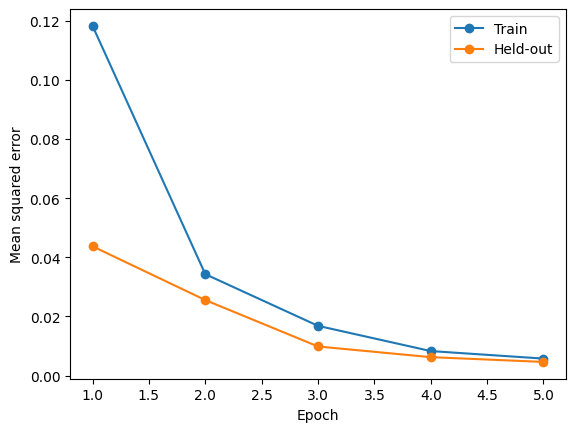

In [8]:
criterion = nn.MSELoss()

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss = 0.0
    for images, _ in loader:
        images = images.to(device)
        reconstruction, _ = model(images)
        total_loss += criterion(reconstruction, images).item() * images.size(0)
    return total_loss / len(loader.dataset)

# Re-running this cell starts a fresh model and optimizer.
torch.manual_seed(42)
model = ImageEncoderDecoder(LATENT_CHANNELS).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
initial_mse = evaluate(model, test_loader)
print(f"Untrained held-out MSE: {initial_mse:.5f}")
history = {"train": [], "test": []}
for epoch in range(EPOCHS):
    model.train()
    total_loss = 0.0
    for images, _ in train_loader:
        images = images.to(device)
        total_loss += train_step(model, images, optimizer, criterion) * images.size(0)
    history["train"].append(total_loss / len(train_loader.dataset))
    history["test"].append(evaluate(model, test_loader))
    print(f"Epoch {epoch + 1}: train MSE={history['train'][-1]:.5f}, "
          f"held-out MSE={history['test'][-1]:.5f}")

plt.plot(range(1, EPOCHS + 1), history["train"], marker="o", label="Train")
plt.plot(range(1, EPOCHS + 1), history["test"], marker="o", label="Held-out")
plt.xlabel("Epoch")
plt.ylabel("Mean squared error")
plt.legend()
plt.show()

## 5. Inspect the reconstruction and latent (10 minutes)
Look for digit identity, stroke thickness, and missing detail. A low average pixel error alone does not guarantee sharp or useful images. Feature maps are learned activations, not necessarily human-readable parts of a digit.

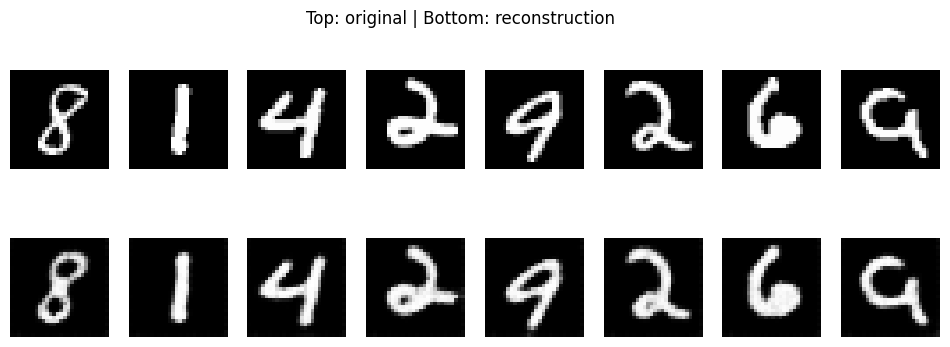

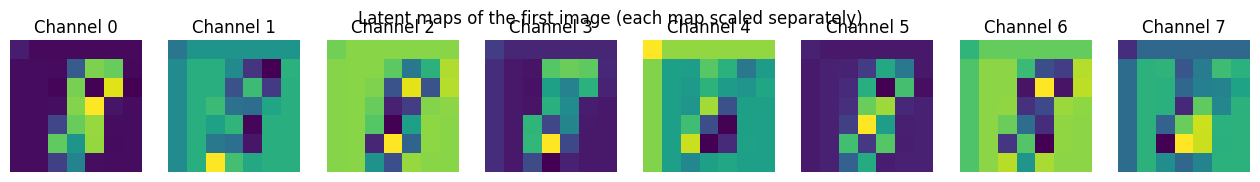

In [9]:
model.eval()
examples, _ = next(iter(test_loader))
with torch.no_grad():
    reconstructed, latents = model(examples[:8].to(device))
reconstructed, latents = reconstructed.cpu(), latents.cpu()
fig, axes = plt.subplots(2, 8, figsize=(12, 4))
for i in range(8):
    axes[0, i].imshow(examples[i, 0], cmap="gray", vmin=0, vmax=1)
    axes[1, i].imshow(reconstructed[i, 0], cmap="gray", vmin=0, vmax=1)
    axes[0, i].axis("off")
    axes[1, i].axis("off")
fig.suptitle("Top: original | Bottom: reconstruction")
plt.show()

count = min(LATENT_CHANNELS, 8)
fig, axes = plt.subplots(1, count, figsize=(2 * count, 2), squeeze=False)
for i in range(count):
    axes[0, i].imshow(latents[0, i], cmap="viridis")
    axes[0, i].set_title(f"Channel {i}")
    axes[0, i].axis("off")
fig.suptitle("Latent maps of the first image (each map scaled separately)")
plt.show()

## 6. Experiment with the bottleneck (10–15 minutes)
Run the lab with `LATENT_CHANNELS = 2`, `8`, and `32`. Change the value in the setup cell and rerun from that cell downward. Keep the data, seed, learning rate, and epoch count fixed. The training cell creates a fresh model each time. Save your observations before the next run.

The following cell automates all three runs with the same subsets, seed, learning rate, and epoch count. It leaves the main eight-channel model intact. Results and discussion follow the comparison plots.


L=2: initial held-out=0.24962, final train=0.01210, final held-out=0.01057
L=8: initial held-out=0.18629, final train=0.00572, final held-out=0.00460
L=32: initial held-out=0.20600, final train=0.00348, final held-out=0.00313


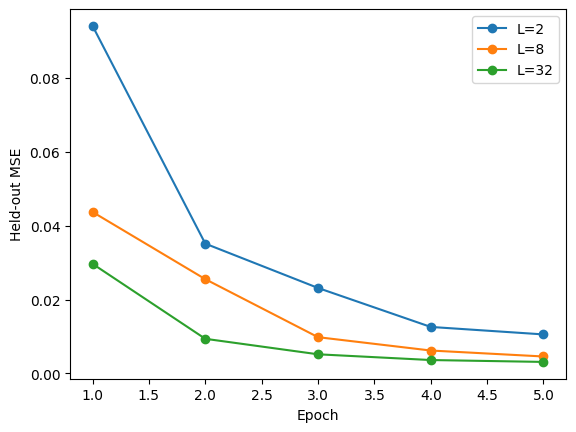

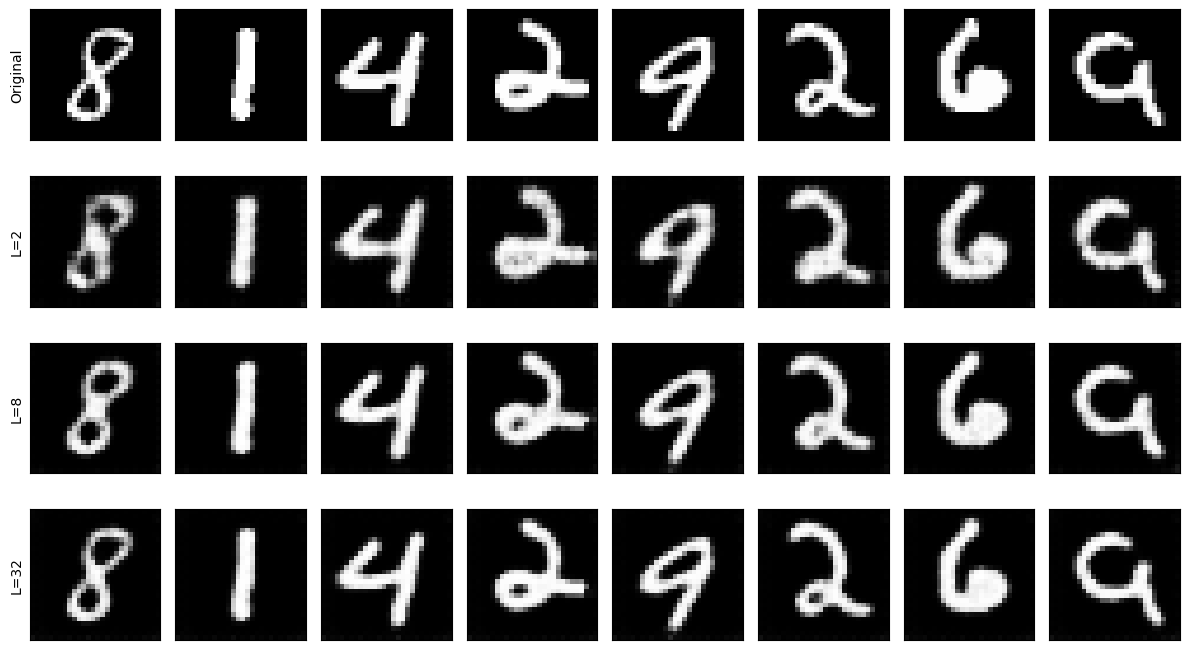

In [10]:
# Repeat the full five-epoch training with each bottleneck size.
# Recreate the loaders after seeding, matching a fresh run of the setup cell.
experiment_results = []
experiment_images = {}
for channels in (2, 8, 32):
    torch.manual_seed(42)
    comparison_train_loader = DataLoader(train_data, batch_size=BATCH_SIZE,
                                         shuffle=True, num_workers=0)
    comparison_test_loader = DataLoader(test_data, batch_size=BATCH_SIZE,
                                        shuffle=False, num_workers=0)
    next(iter(comparison_train_loader))  # Same setup-cell preview consumption.
    shape_model = ImageEncoderDecoder(channels).to(device)
    with torch.no_grad():
        check_x = torch.rand(4, 1, 28, 28, device=device)
        check_reconstruction, check_z = shape_model(check_x)
    assert check_z.shape == (4, channels, 7, 7)
    assert check_reconstruction.shape == check_x.shape
    del shape_model
    torch.manual_seed(42)
    comparison_model = ImageEncoderDecoder(channels).to(device)
    comparison_optimizer = torch.optim.Adam(comparison_model.parameters(), lr=1e-3)
    before = evaluate(comparison_model, comparison_test_loader)
    comparison_history = {"train": [], "test": []}
    for epoch in range(EPOCHS):
        comparison_model.train()
        total = 0.0
        for batch, _ in comparison_train_loader:
            batch = batch.to(device)
            total += train_step(comparison_model, batch, comparison_optimizer, criterion) * batch.size(0)
        comparison_history["train"].append(total / len(train_data))
        comparison_history["test"].append(evaluate(comparison_model, comparison_test_loader))
    experiment_results.append({"channels": channels, "values": channels * 49,
                               "ratio": 784 / (channels * 49),
                               "train": comparison_history["train"][-1],
                               "test": comparison_history["test"][-1]})
    comparison_model.eval()
    with torch.no_grad():
        experiment_images[channels] = comparison_model(examples[:8].to(device))[0].cpu()
    print(f"L={channels}: initial held-out={before:.5f}, "
          f"final train={experiment_results[-1]['train']:.5f}, "
          f"final held-out={experiment_results[-1]['test']:.5f}")
    plt.plot(range(1, EPOCHS + 1), comparison_history["test"], marker="o", label=f"L={channels}")
plt.xlabel("Epoch")
plt.ylabel("Held-out MSE")
plt.legend()
plt.show()
fig, axes = plt.subplots(4, 8, figsize=(12, 7))
for row, (label, batch) in enumerate([("Original", examples)] +
                                    [(f"L={c}", experiment_images[c]) for c in (2, 8, 32)]):
    for col in range(8):
        axes[row, col].imshow(batch[col, 0], cmap="gray", vmin=0, vmax=1)
        axes[row, col].set_xticks([])
        axes[row, col].set_yticks([])
    axes[row, 0].set_ylabel(label)
plt.tight_layout()
plt.show()


### Experiment results and discussion

All runs used 5,000 training images, 1,000 held-out images, seed 42, Adam at 0.001, and five epochs on CPU. Each run started with fresh weights and an optimizer. The comparison grid above shows the same eight held-out images for every model.

| Latent channels | Values per image | Input/latent ratio | Final train MSE | Final held-out MSE | Visible differences |
|---|---|---|---|---|---|
| 2 | 98 | 8:1 | 0.01210 | 0.01057 | Recognizable digits, but blurred edges and softened loops; the 9 has a thicker loop. |
| 8 | 392 | 2:1 | 0.00572 | 0.00460 | Cleaner loops and strokes than L=2; some edges remain soft. |
| 32 | 1568 | 0.5:1 | 0.00348 | 0.00313 | Closest stroke shapes and sharper loop boundaries in these examples; some smoothing remains. |

1. **Did a larger latent help?** Yes in these runs: held-out MSE fell from 0.01057 (2 channels) to 0.00460 (8) and 0.00313 (32). In the grid, the first digit's loops and the fifth digit's loop/stem are closer to the originals with more channels. All three retain digit identity, and some smoothing persists even at 32 channels. This is one seed and a short training schedule; model parameter counts also change, so these results do not isolate latent capacity or prove a universal ranking.
2. **Why is downsampling insufficient?** Dimensionality counts channels as well as spatial positions: C × H × W. Although 7 × 7 is smaller than 28 × 28, 32 × 7 × 7 = 1,568 exceeds the 784 input values. The 2- and 8-channel latents have 98 and 392 values and are dimensionally compressed; the 32-channel latent is not. These ratios count tensor elements, not stored file bytes.
3. **Why can size be restored without all details?** Transposed convolutions learn to map a coarse representation onto a larger grid. Strided encoding can discard information, so increasing the number of output pixels cannot guarantee inversion of the original image. Pixel MSE can also favor smooth reconstructions of uncertain strokes.
4. **How would a `[N, 128]` vector differ?** It has 128 values per image and no explicit spatial axes, whereas this latent is `[N, L, 7, 7]`. A vector decoder needs a learned mapping, such as a linear layer followed by reshaping, to create an initial spatial grid. Its input/latent element ratio would be 784/128 = 6.125:1.
5. **Where could a skip connection go?** The encoder's `[N, 16, 14, 14]` activation could be concatenated with the first decoder's `[N, 16, 14, 14]` activation, with the next layer adjusted for 32 input channels. This supplies finer spatial information but also lets information bypass the 7 × 7 bottleneck, weakening its constraint on the full reconstruction path.
6. **Why is this not a reliable random-image generator?** Training only asks the decoder to reconstruct codes produced by the encoder for real images. It does not fit those codes to a known sampling distribution. Arbitrary random latents may lie outside the learned code distribution, where useful digits are not guaranteed. A generative model needs a way to learn or constrain and sample that distribution.

The held-out subset was used repeatedly for this comparison, so these are validation results rather than an untouched final test benchmark.


## Optional extension: denoising
Keep the architecture and start with a fresh model and optimizer. Add noise to the training **input**, while retaining the clean image as the **target**:

```python
noisy = (images + 0.3 * torch.randn_like(images)).clamp(0, 1)
reconstruction, _ = model(noisy)
loss = criterion(reconstruction, images)
```

Update both training and evaluation to use noisy inputs and clean targets. For evaluation, generate one fixed set of noisy held-out images and reuse it. Compare noisy-input MSE with denoised-output MSE against the clean images, and plot clean/noisy/reconstructed rows. Merely feeding noise to a reconstruction-trained model is not the same as training a denoiser.

An alternative extension is to replace each transposed convolution with 2× bilinear upsampling (`align_corners=False`) followed by a 3×3 convolution with padding 1. Keep the intermediate ReLU and final Sigmoid and check shapes before retraining.

## Submission and assessment
Submit the completed notebook with:
- all four TODOs implemented and shape checks passing (**4 marks**);
- your completed shape table and latent-size calculations (**2 marks**);
- training curves and original/reconstructed images (**2 marks**);
- the three-run experiment table and evidence-based discussion (**2 marks**).

Expected behavior: reconstruction error should generally decrease and reconstructed digits should become recognizable, though some strokes may remain blurred. No fixed MSE threshold is required. If training fails, check the target, output range, gradient update, and tensor shapes before increasing epochs.